In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv("data/olist_orders_dataset.csv",
                     parse_dates=["order_purchase_timestamp",
                                  "order_delivered_customer_date",
                                  "order_estimated_delivery_date"])
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")

print(orders.shape, reviews.shape)
orders.head()

(99441, 8) (99224, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [2]:
df = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]).copy()

# Pozitif = tahmin edilen tarihten geç teslim (gün)
df["delay_days"] = (df["order_delivered_customer_date"]
                    - df["order_estimated_delivery_date"]).dt.days
df["is_late"] = df["delay_days"] > 0

# Bir siparişin birden fazla yorumu olabilir, ortalama puanı al
score = reviews.groupby("order_id")["review_score"].mean().reset_index()
df = df.merge(score, on="order_id", how="inner")

print(df["is_late"].mean())  # geç teslim oranı
print(df.groupby("is_late")["review_score"].mean())

0.06659083319418935
is_late
False    4.290589
True     2.271823
Name: review_score, dtype: float64


                  orders  avg_review
delay_bucket                        
8+ days early      70929        4.32
1-7 days early     17234        4.20
On estimated day    1280        4.04
1-3 days late       1852        3.29
4-7 days late       1748        2.11
8-14 days late      1446        1.67
15+ days late       1335        1.73


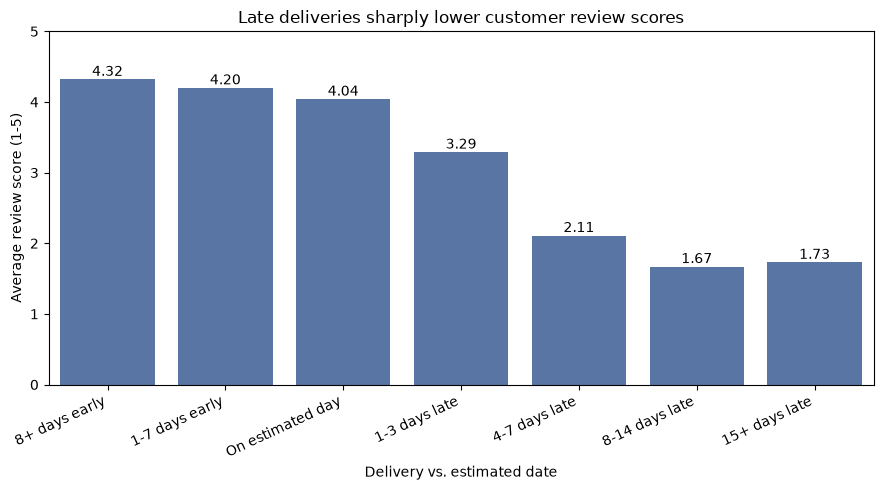

In [3]:
import os
os.makedirs("images", exist_ok=True)

bins = [-float("inf"), -8, -1, 0, 3, 7, 14, float("inf")]
labels = ["8+ days early", "1-7 days early", "On estimated day",
          "1-3 days late", "4-7 days late", "8-14 days late", "15+ days late"]
df["delay_bucket"] = pd.cut(df["delay_days"], bins=bins, labels=labels)

summary = (df.groupby("delay_bucket", observed=True)
             .agg(orders=("order_id", "count"),
                  avg_review=("review_score", "mean"))
             .round(2))
print(summary)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=summary.reset_index(), x="delay_bucket", y="avg_review",
                 color="#4C72B0")
for i, v in enumerate(summary["avg_review"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_ylim(0, 5)
ax.set_xlabel("Delivery vs. estimated date")
ax.set_ylabel("Average review score (1-5)")
ax.set_title("Late deliveries sharply lower customer review scores")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("images/review_by_delay.png", dpi=150)
plt.show()

In [4]:
print("Toplam sipariş:", len(orders))
print("Teslim edilmiş:", (orders["order_status"] == "delivered").sum())
print("Analizdeki sipariş:", len(df))

Toplam sipariş: 99441
Teslim edilmiş: 96478
Analizdeki sipariş: 95824


In [5]:
print(orders["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [6]:
delivered = orders[orders["order_status"] == "delivered"]
print("Teslim edilmiş:", len(delivered))

# Adım 1: teslim tarihi boş olan kaç sipariş var?
bos_tarih = delivered["order_delivered_customer_date"].isna().sum()
print("Teslim tarihi boş:", bos_tarih)

# Teslim tarihi dolu olanlar
tarihli = delivered.dropna(subset=["order_delivered_customer_date"])
print("Tarihi dolu:", len(tarihli))

Teslim edilmiş: 96478
Teslim tarihi boş: 8
Tarihi dolu: 96470


    delay_clipped  orders  avg_review
0             -20   16358    4.302268
1             -19    2693    4.356851
2             -18    3116    4.330552
3             -17    3398    4.337552
4             -16    3888    4.332819
5             -15    5318    4.348815
6             -14    7090    4.329314
7             -13    5926    4.337749
8             -12    4526    4.310760
9             -11    4592    4.302664
10            -10    4618    4.332720
11             -9    4606    4.292987
12             -8    4800    4.257083
13             -7    4815    4.256282
14             -6    3603    4.246739
15             -5    2208    4.195652
16             -4    1903    4.146611
17             -3    1715    4.120117
18             -2    1540    4.125000
19             -1    1450    4.157931
20              0    1280    4.035547
21              1     820    3.731707
22              2     536    3.179104
23              3     496    2.683468
24              4     436    2.497706
25          

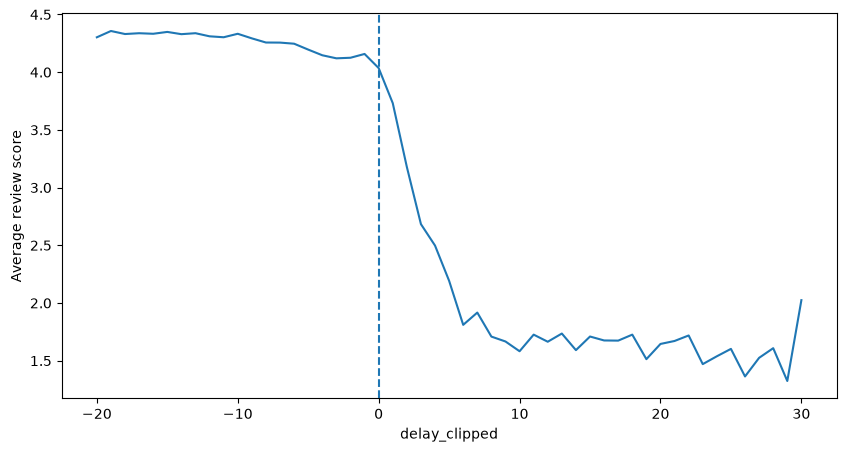

In [9]:
# 1. Uç değerleri sınırla: -20'den az olanlar -20, 30'dan çok olanlar 30 olsun
df["delay_clipped"] = df["delay_days"].clip(-20, 30)

# 2. Her gecikme günü için sipariş sayısı ve ortalama puan
by_day = (df.groupby("delay_clipped")
            .agg(orders=("order_id", "count"),
                 avg_review=("review_score", "mean"))
            .reset_index())
print(by_day)

# 3. Çizgi grafiği
plt.figure(figsize=(10, 5))
plt.plot(by_day["delay_clipped"], by_day["avg_review"])
plt.axvline(0, linestyle="--")   # 0 = tahmini teslim günü
plt.xlabel("delay_clipped")
plt.ylabel("Average review score")
plt.show()

In [10]:
df.groupby("delay_clipped")["review_score"].std()

delay_clipped
-20    1.172821
-19    1.089779
-18    1.129714
-17    1.115606
-16    1.107292
-15    1.102466
-14    1.141974
-13    1.108673
-12    1.134605
-11    1.131248
-10    1.096100
-9     1.146525
-8     1.171371
-7     1.146765
-6     1.136096
-5     1.206007
-4     1.206819
-3     1.223018
-2     1.236148
-1     1.202233
 0     1.246930
 1     1.388500
 2     1.588984
 3     1.671692
 4     1.651887
 5     1.527413
 6     1.372166
 7     1.380542
 8     1.225455
 9     1.250076
 10    1.108449
 11    1.301137
 12    1.169290
 13    1.269052
 14    1.151677
 15    1.167569
 16    1.197460
 17    1.203926
 18    1.193271
 19    1.023602
 20    1.129462
 21    1.258445
 22    1.161126
 23    1.079711
 24    1.056475
 25    1.204047
 26    0.929320
 27    0.960435
 28    1.125034
 29    0.783654
 30    1.510237
Name: review_score, dtype: float64

In [11]:
# 1. Toplam teslimat süresi (gün): sipariş verildiğinden teslimata kadar
df["total_days"] = (df["order_delivered_customer_date"]
                    - df["order_purchase_timestamp"]).dt.days

# 2. Süreyi gruplara böl
bins = [-1, 7, 14, 21, float("inf")]
labels = ["0-7 days", "8-14 days", "15-21 days", "22+ days"]
df["duration_bucket"] = pd.cut(df["total_days"], bins=bins, labels=labels)

# 3. Her süre grubunda, geç ve zamanında gelenleri ayrı ayrı özetle
table = (df.groupby(["duration_bucket", "is_late"], observed=True)
           .agg(orders=("order_id", "count"),
                avg_review=("review_score", "mean"))
           .round(2)
           .unstack("is_late"))
print(table)

                orders       avg_review      
is_late          False True       False True 
duration_bucket                              
0-7 days         33446    93       4.41  3.88
8-14 days        35849   341       4.30  3.26
15-21 days       14620   644       4.15  2.96
22+ days          5528  5303       3.88  2.10


In [12]:
customers = pd.read_csv("data/olist_customers_dataset.csv")

n_before = len(df)
df = df.merge(customers[["customer_id", "customer_state"]],
              on="customer_id", how="left")
print(n_before, len(df))   # eşit olmalı

# 1. Eyalet bazında özet
by_state = (df.groupby("customer_state")
              .agg(orders=("order_id", "count"),
                   late_rate=("is_late", "mean"),
                   avg_review=("review_score", "mean"))
              .round(3)
              .sort_values("orders", ascending=False))
print(by_state.head(10))

# 2. En büyük 10 eyalette, aynı eyalet içinde geç vs zamanında
top_states = by_state.head(10).index
within = (df[df["customer_state"].isin(top_states)]
            .groupby(["customer_state", "is_late"])
            .agg(orders=("order_id", "count"),
                 avg_review=("review_score", "mean"))
            .round(2)
            .unstack("is_late"))
print(within)

95824 95824
                orders  late_rate  avg_review
customer_state                               
SP               40266      0.044       4.247
RJ               12211      0.119       3.965
MG               11285      0.045       4.192
RS                5326      0.060       4.186
PR                4900      0.040       4.240
SC                3519      0.081       4.133
BA                3229      0.119       3.930
DF                2070      0.057       4.134
ES                1969      0.104       4.080
GO                1946      0.064       4.104
               orders       avg_review      
is_late         False True       False True 
customer_state                              
BA               2845   384       4.14  2.36
DF               1952   118       4.26  1.97
ES               1764   205       4.26  2.51
GO               1822   124       4.23  2.21
MG              10780   505       4.28  2.36
PR               4706   194       4.30  2.68
RJ              10755  1456    

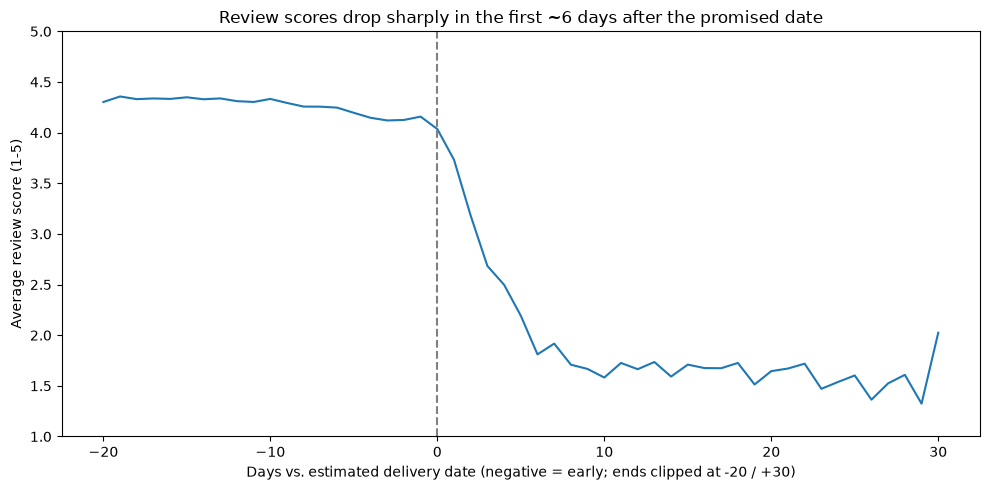

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(by_day["delay_clipped"], by_day["avg_review"])
plt.axvline(0, linestyle="--", color="gray")
plt.ylim(1, 5)
plt.xlabel("Days vs. estimated delivery date (negative = early; ends clipped at -20 / +30)")
plt.ylabel("Average review score (1-5)")
plt.title("Review scores drop sharply in the first ~6 days after the promised date")
plt.tight_layout()
plt.savefig("images/review_by_delay_days.png", dpi=150)
plt.show()

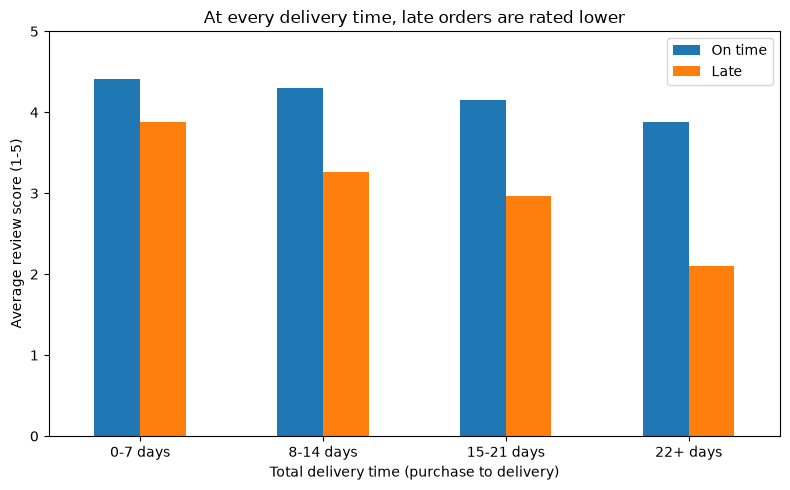

In [14]:
ax = table["avg_review"].plot(kind="bar", figsize=(8, 5))
ax.legend(["On time", "Late"])
ax.set_ylim(0, 5)
ax.set_xlabel("Total delivery time (purchase to delivery)")
ax.set_ylabel("Average review score (1-5)")
ax.set_title("At every delivery time, late orders are rated lower")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("images/review_by_duration_and_lateness.png", dpi=150)
plt.show()